
RESULTADO DE LA SOLICITUD
Cliente: Santiago
Edad: 25
Ingresos: 3000000.0
Score: 800
Endeudamiento: 20.0 %
Monto solicitado: $ 40000000.0
Plazo solicitado: 5.0 años

DECISIÓN: REVISIÓN
EXPLICACIÓN: El cliente presenta condiciones intermedias y necesita una evaluación adicional.

CONTRAOFERTA GENERADA
Monto solicitado originalmente: $ 40000000.0
Nuevo monto sugerido: $ 40000000.0
Nuevo plazo: 5.83 años
Cuota mensual: $ 897174.43
Capacidad de pago: MEDIA
Decisión del motor para la contraoferta: APROBADO
Fitness: 0.8366
Utilidad del cliente: 0.9138
Utilidad del prestamista: 0.5133


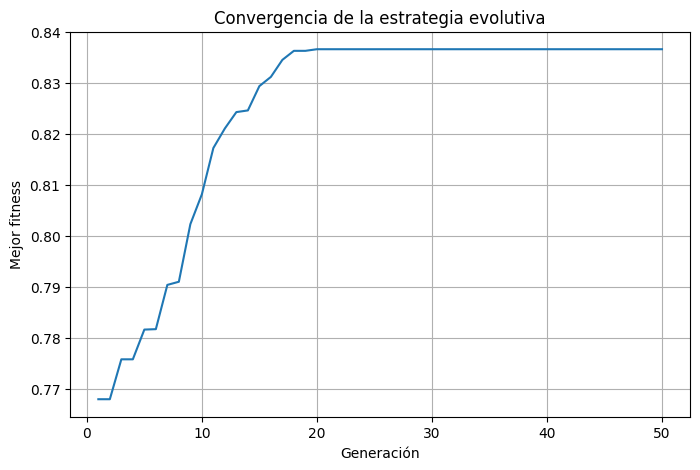

In [6]:
import random
import matplotlib.pyplot as plt


# 1. FUNCIÓN PARA INGRESAR LOS DATOS DEL CLIENTE

def ingresar_datos():
    cliente = {}
    cliente["nombre"] = input("Nombre del cliente: ")
    cliente["edad"] = int(input("Edad del cliente: "))
    cliente["ingreso_mensual"] = float(input("Ingreso mensual: "))
    cliente["monto_credito"] = float(input("Monto solicitado: "))
    cliente["plazo"] = float(input("Plazo solicitado (años): "))
    cliente["tasa_anual"] = float(input("Tasa de interés efectiva anual (%): "))
    cliente["score"] = int(input("Score crediticio: "))
    cliente["endeudamiento"] = float(input("Nivel de endeudamiento (%): "))
    cliente["antiguedad_empleo_actual"] = float(input("Antigüedad en el empleo actual (años): "))
    cliente["reportes_negativos"] = int(input("Número de reportes negativos: "))

    if cliente["ingreso_mensual"] <= 0 or cliente["monto_credito"] <= 0:
        raise ValueError("El ingreso y el monto deben ser positivos.")
    if not 0 < cliente["plazo"] <= 20:
        raise ValueError("El plazo debe ser mayor que 0 y máximo 20 años.")
    if round(cliente["plazo"] * 12) != cliente["plazo"] * 12:
        raise ValueError("El plazo debe corresponder a meses completos (por ejemplo, 5 o 5.5 años).")
    if cliente["tasa_anual"] < 0:
        raise ValueError("La tasa efectiva anual no puede ser negativa.")
    if not 0 <= cliente["endeudamiento"] <= 100 or cliente["score"] < 0:
        raise ValueError("Revisa el score y el porcentaje de endeudamiento.")
    if cliente["reportes_negativos"] < 0 or cliente["antiguedad_empleo_actual"] < 0:
        raise ValueError("Los reportes y la antigüedad no pueden ser negativos.")
    return cliente

# 2. EVALUAR EL SCORE CREDITICIO

def evaluar_score(score):

    if score >= 750:
        return "BUENO"

    elif score >= 550:
        return "REGULAR"

    else:
        return "MALO"


# 3. EVALUAR EL NIVEL DE ENDEUDAMIENTO

def evaluar_endeudamiento(endeudamiento):

    if endeudamiento <= 40:
        return "BAJO"

    elif endeudamiento <= 60:
        return "MEDIO"

    else:
        return "ALTO"


# 4. EVALUAR ESTABILIDAD LABORAL

def evaluar_estabilidad_actual(antiguedad_actual, edad):

    if 17 <= edad <= 20:

        if antiguedad_actual >= 1:
            return "ESTABLE"

        else:
            return "N/A"

    elif 21 <= edad <= 24:

        if antiguedad_actual >= 1:
            return "ESTABLE"

        else:
            return "MEDIA"

    elif 25 <= edad <= 35:

        if antiguedad_actual >= 4:
            return "ESTABLE"

        elif antiguedad_actual >= 2:
            return "MEDIA"

        else:
            return "BAJA"

    elif 36 <= edad <= 50:

        if antiguedad_actual >= 6:
            return "ESTABLE"

        elif antiguedad_actual >= 4:
            return "MEDIA"

        else:
            return "BAJA"

    elif 51 <= edad <= 65:

        if antiguedad_actual >= 8:
            return "ESTABLE"

        elif antiguedad_actual >= 6:
            return "MEDIA"

        else:
            return "BAJA"

    else:
        return "N/A"

# 5. CONVERTIR TASA

def convertir_tasa_mensual(tasa_anual):
    tasa_decimal = tasa_anual / 100
    tasa_mensual = (1 + tasa_decimal) ** (1 / 12) - 1
    return tasa_mensual

# 6. CALCULAR CUOTA

def calcular_cuota(monto_credito, plazo, tasa_anual):
    tasa_mensual = convertir_tasa_mensual(tasa_anual)
    meses = round(plazo * 12)
    if meses <= 0:
        raise ValueError("El plazo debe ser positivo.")
    if tasa_mensual == 0:
        return monto_credito / meses
    return monto_credito * tasa_mensual / (1 - (1 + tasa_mensual) ** (-meses))

# 7. EVALUAR CAPACIDAD DE PAGO

def evaluar_capacidad_pago(cuota, ingreso_mensual):

    relacion = cuota / ingreso_mensual

    if 0 <= relacion <= 0.2:
        return "BUENA"

    elif 0.2 < relacion <= 0.3:
        return "MEDIA"

    elif 0.3 < relacion <= 0.4:
        return "REVISAR"

    else:
        return "BAJA"


# 8. MOTOR DE INFERENCIA

def motor_inferencia(cliente):

    perfil_score = evaluar_score(
        cliente["score"]
    )

    nivel_deuda = evaluar_endeudamiento(
        cliente["endeudamiento"]
    )

    estabilidad_actual = evaluar_estabilidad_actual(
        cliente["antiguedad_empleo_actual"],
        cliente["edad"]
    )

    cuota = calcular_cuota(
    cliente["monto_credito"],
    cliente["plazo"],
    cliente["tasa_anual"]
    )

    capacidad_pago = evaluar_capacidad_pago(
        cuota,
        cliente["ingreso_mensual"]
    )

    # REGLAS DE RECHAZO

    if capacidad_pago == "BAJA":

        return (
            "RECHAZADO",
            "El cliente no tiene suficiente capacidad de pago."
        )

    if cliente["reportes_negativos"] >= 2:

        return (
            "RECHAZADO",
            "El cliente tiene dos o más reportes negativos."
        )

    if perfil_score == "MALO":

        return (
            "RECHAZADO",
            "El score crediticio es demasiado bajo."
        )

    if nivel_deuda == "ALTO":

        return (
            "RECHAZADO",
            "El nivel de endeudamiento es demasiado alto."
        )

    # REGLAS DE APROBACIÓN

    if (
        perfil_score == "BUENO"
        and nivel_deuda == "BAJO"

        and (
            estabilidad_actual == "ESTABLE"
            or estabilidad_actual == "N/A"
        )

        and (
            capacidad_pago == "BUENA"

            or (
                capacidad_pago == "MEDIA"
                and nivel_deuda == "BAJO"
            )
        )

        and cliente["reportes_negativos"] == 0
    ):

        return (
            "APROBADO",
            "El cliente presenta un buen perfil financiero."
        )

    # REGLAS DE REVISIÓN

    if (
        perfil_score == "REGULAR"
        or capacidad_pago == "REVISAR"
        or nivel_deuda == "MEDIO"
        or estabilidad_actual == "MEDIA"
        or cliente["reportes_negativos"] == 1
    ):

        return (
            "REVISIÓN",
            "El cliente presenta condiciones intermedias "
            "y necesita una evaluación adicional."
        )

    return (
        "REVISIÓN",
        "La solicitud necesita ser revisada con mayor detalle."
    )


# 9. MOSTRAR RESULTADOS

def mostrar_resultado(cliente, decision, explicacion):

    print("\nRESULTADO DE LA SOLICITUD")

    print("Cliente:", cliente["nombre"])
    print("Edad:", cliente["edad"])
    print("Ingresos:", cliente["ingreso_mensual"])
    print("Score:", cliente["score"])
    print("Endeudamiento:", cliente["endeudamiento"], "%")
    print("Monto solicitado: $", cliente["monto_credito"])
    print("Plazo solicitado:", cliente["plazo"], "años")

    print("\nDECISIÓN:", decision)
    print("EXPLICACIÓN:", explicacion)


# 10. CREAR UN INDIVIDUO

def crear_individuo(cliente):
    monto_original = cliente["monto_credito"]
    meses_original = round(cliente["plazo"] * 12)
    monto = random.uniform(monto_original * 0.70, monto_original)
    meses = random.randint(meses_original, 240)
    return [monto, meses / 12]

# 11. CREAR POBLACIÓN INICIAL

def crear_poblacion(cliente, tamaño=20):

    poblacion = []

    for i in range(tamaño):

        individuo = crear_individuo(
            cliente
        )

        poblacion.append(
            individuo
        )

    return poblacion


# 12. CALCULAR FITNESS

def calcular_fitness(individuo, cliente):
    monto, plazo = individuo
    monto_original = cliente["monto_credito"]
    plazo_original = cliente["plazo"]
    cuota = calcular_cuota(monto, plazo, cliente["tasa_anual"])
    capacidad = max(0, min(1, 1 - cuota / cliente["ingreso_mensual"]))
    cercania_monto = max(0, min(1, monto / monto_original))
    if plazo_original == 20:
        cercania_plazo = 1
    else:
        cercania_plazo = max(0, min(1, 1 - (plazo - plazo_original) / (20 - plazo_original)))

    # Penalizar ofertas que el motor no aprobaría
    oferta = cliente.copy()
    oferta["monto_credito"] = monto
    oferta["plazo"] = plazo
    decision, _ = motor_inferencia(oferta)
    penalizacion = 0 if decision == "APROBADO" else 1
    return (0.50 * capacidad + 0.25 * cercania_monto
            + 0.25 * cercania_plazo - penalizacion)

def calcular_intereses_totales(monto, plazo, tasa_anual):

    cuota = calcular_cuota(
        monto, plazo, tasa_anual
    )

    meses = plazo * 12

    intereses = cuota * meses - monto

    return intereses

# 13. UTILIDAD DEL CLIENTE


def utilidad_cliente(monto, plazo, cliente):

    monto_original = cliente["monto_credito"]
    plazo_original = cliente["plazo"]
    tasa_anual = cliente["tasa_anual"]

    cercania_monto = monto / monto_original

    if plazo_original == 20:
        cercania_plazo = 1
    else:
        cercania_plazo = 1 - (
            (plazo - plazo_original)
            / (20 - plazo_original)
        )

    intereses = calcular_intereses_totales(
        monto, plazo, tasa_anual
    )

    intereses_referencia = calcular_intereses_totales(
        monto_original, 20, tasa_anual
    )

    if intereses_referencia == 0:
        conveniencia_intereses = 1
    else:
        conveniencia_intereses = 1 - (
            intereses / intereses_referencia
        )

    conveniencia_intereses = max(
        0, min(1, conveniencia_intereses)
    )

    utilidad = (
        0.40 * cercania_monto
        + 0.30 * cercania_plazo
        + 0.30 * conveniencia_intereses
    )

    return utilidad

# 14. UTILIDAD DEL PRESTAMISTA

def utilidad_prestamista(monto, plazo, cliente):

    tasa_anual = cliente["tasa_anual"]
    ingreso = cliente["ingreso_mensual"]
    monto_original = cliente["monto_credito"]

    cuota = calcular_cuota(
        monto, plazo, tasa_anual
    )

    relacion = cuota / ingreso

    capacidad = 1 - relacion
    capacidad = max(0, min(1, capacidad))

    intereses = calcular_intereses_totales(
        monto, plazo, tasa_anual
    )

    intereses_referencia = calcular_intereses_totales(
        monto_original, 20, tasa_anual
    )

    if intereses_referencia == 0:
        ingresos_intereses = 0
    else:
        ingresos_intereses = (
            intereses / intereses_referencia
        )

    ingresos_intereses = max(
        0, min(1, ingresos_intereses)
    )

    utilidad = (
        0.60 * capacidad
        + 0.40 * ingresos_intereses
    )

    return utilidad

# 15. MUTACIÓN

def mutar(individuo, cliente):
    hijo = individuo.copy()
    hijo[0] += random.uniform(-0.05, 0.05) * cliente["monto_credito"]
    meses = round(hijo[1] * 12) + random.randint(-6, 6)
    hijo[1] = meses / 12
    return hijo

# REPARAR INDIVIDUO

def reparar(individuo, cliente):
    monto_original = cliente["monto_credito"]
    individuo[0] = max(monto_original * 0.70, min(monto_original, individuo[0]))
    meses_original = round(cliente["plazo"] * 12)
    meses = max(meses_original, min(240, round(individuo[1] * 12)))
    individuo[1] = meses / 12
    return individuo

# 17. ESTRATEGIA EVOLUTIVA

def estrategia_evolutiva(
    cliente,
    mu=6,
    lambda_=12,
    generaciones=50
):

    historial_fitness = []

    # Crear población inicial

    poblacion = crear_poblacion(
        cliente,
        tamaño=mu
    )

    # Proceso evolutivo

    for generacion in range(
        generaciones
    ):

        # Ordenar la población de mayor a menor fitness

        poblacion.sort(
            key=lambda individuo:
            calcular_fitness(
                individuo,
                cliente
            ),
            reverse=True
        )

        # Seleccionar los mejores padres

        padres = (
            poblacion[:mu]
        )

        # Crear descendientes

        descendientes = []

        for i in range(
            lambda_
        ):

            padre = random.choice(
                padres
            )

            hijo = mutar(
                padre,
                cliente
            )

            hijo = reparar(
                hijo,
                cliente
            )

            descendientes.append(
                hijo
            )

        # Juntar padres y descendientes

        candidatos = (
            padres
            + descendientes
        )

        # Ordenar candidatos de mayor a menor fitness

        candidatos.sort(
            key=lambda individuo:
            calcular_fitness(
                individuo,
                cliente
            ),
            reverse=True
        )

        # Sobreviven los mejores individuos

        poblacion = (
            candidatos[:mu]
        )

        # Guardar el mejor fitness de la generación

        mejor_fitness_generacion = (
            calcular_fitness(
                poblacion[0],
                cliente
            )
        )

        historial_fitness.append(
            mejor_fitness_generacion
        )

    # Seleccionar el mejor individuo final

    mejor_individuo = (
        poblacion[0]
    )

    mejor_fitness = (
        calcular_fitness(
            mejor_individuo,
            cliente
        )
    )

    return (
        mejor_individuo,
        mejor_fitness,
        historial_fitness
    )


# GRAFICAR CONVERGENCIA

def graficar_convergencia(historial_fitness):

    generaciones = range(
        1,
        len(historial_fitness) + 1
    )

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        generaciones,
        historial_fitness
    )

    plt.xlabel(
        "Generación"
    )

    plt.ylabel(
        "Mejor fitness"
    )

    plt.title(
        "Convergencia de la estrategia evolutiva"
    )

    plt.grid()

    plt.show()


# MOSTRAR CONTRAOFERTA

def mostrar_contraoferta(
    cliente,
    individuo,
    fitness
):

    monto = individuo[0]
    plazo = individuo[1]

    cuota = calcular_cuota(
    monto,
    plazo,
    cliente["tasa_anual"]
    )

    capacidad = evaluar_capacidad_pago(
    cuota,
    cliente["ingreso_mensual"]
    )

    utilidad_c = utilidad_cliente(
        monto,
        plazo,
        cliente
    )

    utilidad_p = utilidad_prestamista(
        monto,
        plazo,
        cliente
    )

    print("\nCONTRAOFERTA GENERADA")
    print("Monto solicitado originalmente: $",round(cliente["monto_credito"],2))
    print("Nuevo monto sugerido: $", round(monto, 2))
    print("Nuevo plazo:", round(plazo, 2), "años")
    print("Cuota mensual: $", round(cuota, 2))
    print("Capacidad de pago:", capacidad)
    oferta = cliente.copy()
    oferta["monto_credito"] = monto
    oferta["plazo"] = plazo
    decision_oferta, _ = motor_inferencia(oferta)
    print("Decisión del motor para la contraoferta:", decision_oferta)
    print("Fitness:",round(fitness,4))
    print("Utilidad del cliente:",round(utilidad_c,4))
    print("Utilidad del prestamista:",round(utilidad_p,4))


# 20. PROGRAMA PRINCIPAL

cliente = ingresar_datos()

decision, explicacion = (
    motor_inferencia(
        cliente
    )
)

mostrar_resultado(
    cliente,
    decision,
    explicacion
)


# ACTIVAR ESTRATEGIA EVOLUTIVA

if decision == "REVISIÓN":

    (
        mejor_individuo,
        mejor_fitness,
        historial
    ) = estrategia_evolutiva(
        cliente,
        mu=6,
        lambda_=12,
        generaciones=50
    )

    # Mostrar mejor contraoferta

    mostrar_contraoferta(
        cliente,
        mejor_individuo,
        mejor_fitness
    )

    # Mostrar curva de convergencia

    graficar_convergencia(
        historial
    )